# CISCaRL: Interpretable Survival Subgroup Discovery on ACTG175

**Objective.** Estimate the 730-day progression-free survival-probability contrast
and discover an interpretable high-benefit subgroup, with validation-based
commitment or abstention.

**Research questions.** (1) Can a support-constrained rule beat max-mean selection?
(2) Can validation-based commitment avoid treating null-benefit patients? (3) How
does the model compare with SCRE on the same data?

**Notebook map.** Part 1 preprocessing → Part 2 estimand → Part 3 model training →
Part 4 validation and commitment → Part 5 assessment → Part 6 SCRE → Part 7
simulation evidence → Part 8 interpretation → Part 9 conclusions.

## Part 0 — Notebook setup

In [1]:
import os, sys, warnings, contextlib, io
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t as tdist, spearmanr
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 60)

ROOT = Path.cwd()
if not (ROOT / "ciscarl2").exists() and (ROOT.parent / "ciscarl2").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

CAND = [
    Path(os.path.expanduser("~")) / "Downloads" / "Machine-Learning-Project" / "data" / "ACTG175.csv",
    ROOT / "Machine-Learning-Project" / "data" / "ACTG175.csv",
    ROOT / "data" / "ACTG175.csv",
]
DATA_PATH = next((p for p in CAND if p.exists()), CAND[0])

from ciscarl2 import dgp
from ciscarl2.estimators import (crossfit_nuisances, truncate_weights,
                                 phi_on_holdout, aipw, ipcw_outcome)
from ciscarl2.gate2 import pseudo_outcome
from ciscarl2.gate11 import _cart
from ciscarl2.gate13 import _holdout
from ciscarl2.gate22 import _stats
from ciscarl2.rules import eval_rule

TSTAR = 730.0
SEED = 2024
SUPPORT_MIN = 200
print("ROOT:", ROOT)
print("DATA:", DATA_PATH, "exists:", DATA_PATH.exists())

ROOT: C:\Users\roshn\OneDrive\Desktop\Amrita\SEM 5\ML\Project
DATA: C:\Users\roshn\Downloads\Machine-Learning-Project\data\ACTG175.csv exists: True


## Part 1 — ACTG175 dataset preprocessing

In [2]:
raw = pd.read_csv(DATA_PATH)
print("shape:", raw.shape)
display(raw.head())
print("columns:", list(raw.columns))
print("missing (top 8):")
display(raw.isna().sum().sort_values(ascending=False).head(8))

shape: (2139, 27)


,pidnum,age,wtkg,hemo,homo,drugs,karnof,oprior,z30,zprior,preanti,race,gender,str2,strat,symptom,treat,offtrt,cd40,cd420,cd496,r,cd80,cd820,cens,days,arms
0,10056,48,89.8128,0,0,0,100,0,0,1,0,0,0,0,1,0,1,0,422,477,660.0,1,566,324,0,948,2
1,10059,61,49.4424,0,0,0,90,0,1,1,895,0,0,1,3,0,1,0,162,218,NaN,0,392,564,1,1002,3
2,10089,45,88.4520,0,1,1,90,0,1,1,707,0,1,1,3,0,1,1,326,274,122.0,1,2063,1893,0,961,3
3,10093,47,85.2768,0,1,0,100,0,1,1,1399,0,1,1,3,0,1,0,287,394,NaN,0,1590,966,0,1166,3
4,10124,43,66.6792,0,1,0,100,0,1,1,1352,0,1,1,3,0,0,0,504,353,660.0,1,870,782,0,1090,0


columns: ['pidnum', 'age', 'wtkg', 'hemo', 'homo', 'drugs', 'karnof', 'oprior', 'z30', 'zprior', 'preanti', 'race', 'gender', 'str2', 'strat', 'symptom', 'treat', 'offtrt', 'cd40', 'cd420', 'cd496', 'r', 'cd80', 'cd820', 'cens', 'days', 'arms']
missing (top 8):


cd496     797
age         0
pidnum      0
hemo        0
homo        0
drugs       0
karnof      0
oprior      0
dtype: int64

In [3]:
COVARIATES = list(dgp.COVARIATES)
print("12 covariates:", COVARIATES)

raw = raw[raw["arms"].isin([0, 1])].reset_index(drop=True)
print("arms 0/1 shape:", raw.shape)
print("missing in the 12 covariates:", int(raw[COVARIATES].isna().sum().sum()))
print("duplicate rows:", int(raw.duplicated().sum()))

X_raw = raw[COVARIATES].to_numpy(float)
A = (raw["arms"] == 1).to_numpy(int)
T = raw["days"].to_numpy(float)
E = raw["cens"].to_numpy(int)
print("X:", X_raw.shape, "| treated share:", round(float(A.mean()), 3),
      "| T range:", float(T.min()), float(T.max()),
      "| event share:", round(float(E.mean()), 3))

12 covariates: ['cd40', 'cd80', 'age', 'wtkg', 'karnof', 'hemo', 'homo', 'race', 'gender', 'drugs', 'str2', 'symptom']
arms 0/1 shape: (1054, 27)
missing in the 12 covariates: 0
duplicate rows: 0
X: (1054, 12) | treated share: 0.495 | T range: 33.0 1231.0 | event share: 0.269


### Split and scaling

The split is made **before** any scaling. The scaler is fitted on discovery only
and applied to validation and assessment, so no assessment information enters
preprocessing.

In [4]:
idx = np.arange(len(X_raw))
disc, hold = train_test_split(idx, test_size=0.5, random_state=SEED, stratify=A)
val, asm = train_test_split(hold, test_size=0.5, random_state=SEED + 1,
                            stratify=A[hold])
print("discovery / validation / assessment:", len(disc), len(val), len(asm))
print("disjoint:", len(set(disc) & set(val)) == 0 and
      len(set(disc) & set(asm)) == 0 and len(set(val) & set(asm)) == 0)

discovery / validation / assessment: 527 263 264
disjoint: True


In [5]:
mu = X_raw[disc].mean(0)
sd = X_raw[disc].std(0)
sd[sd == 0] = 1.0
X = (X_raw - mu) / sd

XD, XV, XA = X[disc], X[val], X[asm]
AD, AV, AA = A[disc], A[val], A[asm]
TD, TV, TA = T[disc], T[val], T[asm]
ED, EV, EA = E[disc], E[val], E[asm]

print("scaler fitted on discovery only")
display(pd.DataFrame({"feature": COVARIATES,
                      "discovery mean": mu.round(2),
                      "discovery sd": sd.round(2)}))

scaler fitted on discovery only


,feature,discovery mean,discovery sd
0,cd40,353.07,121.26
1,cd80,1002.85,484.19
2,age,35.19,8.82
3,wtkg,75.64,13.89
4,karnof,95.45,5.82
5,hemo,0.09,0.29
6,homo,0.67,0.47
7,race,0.28,0.45
8,gender,0.83,0.37
9,drugs,0.13,0.34


In [6]:
assert len(disc) + len(val) + len(asm) == len(X_raw)
assert len(set(disc) & set(val)) == 0
assert len(set(disc) & set(asm)) == 0
assert len(set(val) & set(asm)) == 0
assert XD.shape[1] == len(COVARIATES)
assert set(np.unique(AD)).issubset({0, 1})
print("PASS: disjoint splits, 12 features, binary treatment")

display(pd.DataFrame({
    "partition": ["discovery", "validation", "assessment"],
    "n": [len(disc), len(val), len(asm)],
    "treated": [int(AD.sum()), int(AV.sum()), int(AA.sum())],
    "events": [int(ED.sum()), int(EV.sum()), int(EA.sum())],
    "censored before 730": [
        int(((TD <= TSTAR) & (ED == 0)).sum()),
        int(((TV <= TSTAR) & (EV == 0)).sum()),
        int(((TA <= TSTAR) & (EA == 0)).sum())],
}))

PASS: disjoint splits, 12 features, binary treatment


,partition,n,treated,events,censored before 730
0,discovery,527,261,137,49
1,validation,263,130,71,36
2,assessment,264,131,76,18


## Part 2 — Define the survival estimand

* **Endpoint:** composite of CD4 decline ≥ 50, AIDS progression, or death.
* **Horizon:** 730 days.
* **Estimand:** τ(730|x) = S₁(730|x) − S₀(730|x), under the observed follow-up
  process. This is **not** an intention-to-treat contrast and **not** a hazard ratio.
* **Subgroup estimand:** τ(r) = E[τ(X) | X ∈ r].

In [7]:
display(pd.DataFrame({
    "arm": ["control (AZT)", "treated (AZT+ddI)"],
    "n": [int((A == 0).sum()), int((A == 1).sum())],
    "events": [int(((A == 0) & (E == 1)).sum()),
               int(((A == 1) & (E == 1)).sum())],
    "censored before 730": [
        int(((A == 0) & (T <= TSTAR) & (E == 0)).sum()),
        int(((A == 1) & (T <= TSTAR) & (E == 0)).sum())],
}))

,arm,n,events,censored before 730
0,control (AZT),532,181,58
1,treated (AZT+ddI),522,103,45


## Part 3 - CISCaRL model training

**Naming.** The method is **CISCaRL**. This notebook runs its frozen
configuration, **C200**: the 200 is the minimum number of discovery patients
a candidate leaf must contain, not a count of trees or iterations. C200 is a
configuration of the model, not a second model.

**Model card (frozen).** Treatment is randomized in ACTG175, so the propensity is
e = 0.5 and no propensity model is fitted.

| component | setting |
|---|---|
| outcome nuisance | per-arm Cox, 5-fold cross-fitted |
| censoring nuisance | conditional Cox model |
| weight cap | min(Q0.99, 20) per fold |
| target | AIPW pseudo-outcome psi |
| discovery learner | depth-3 CART, min_samples_leaf = 60 |
| selection | max discovery mean psi with support >= 200 |
| commitment | validation one-sided 95% LCB > 0 |
| prediction fallback | discovery marginal ATE |
| decision fallback | no treatment (abstain) |
| prediction calibration | empirical-Bayes shrinkage toward the marginal ATE (C200-S); never changes the decision |

In [8]:
muD, GD, Gmarg, fid, fcaps, _ = crossfit_nuisances(
    XD, AD, TD, ED, TSTAR, seed=SEED, return_folds=True)
GD, cap = truncate_weights(GD, fid, fcaps)

print("fold sizes:", np.bincount(fid).tolist())
print("cap per fold:", [round(min(fcaps[k][0.99], 20.0), 2)
                        for k in sorted(fcaps)])

fold sizes: [106, 106, 105, 105, 105]
cap per fold: [1.31, 1.34, 1.21, 1.33, 1.29]


In [9]:
w = ipcw_outcome(TD, TSTAR, GD)
nz = w[w > 0]
print("weights > 0:", len(nz))
print("max weight:", round(float(nz.max()), 2))
print("99th percentile:", round(float(np.percentile(nz, 99)), 2))
print("effective sample size:", round(float((w.sum() ** 2) / (w ** 2).sum()), 1))
print("censored before 730:", round(float(np.mean((TD <= TSTAR) & (ED == 0))), 3))

weights > 0: 376
max weight: 1.34
99th percentile: 1.32
effective sample size: 374.8
censored before 730: 0.093


psi mean: 0.1598 | psi sd: 0.9932


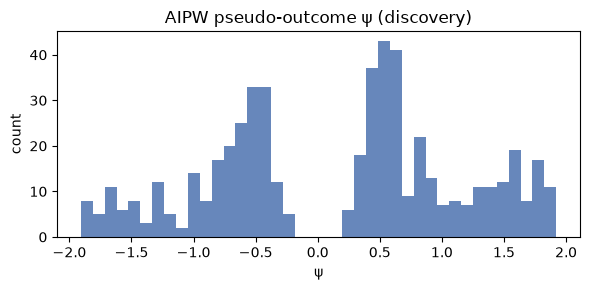

In [10]:
psi = pseudo_outcome(AD, TD, TSTAR, muD, GD)
print("psi mean:", round(float(psi.mean()), 4),
      "| psi sd:", round(float(psi.std()), 4))

fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(psi, bins=40, color="#4c72b0", alpha=0.85)
ax.set_title("AIPW pseudo-outcome ψ (discovery)")
ax.set_xlabel("ψ")
ax.set_ylabel("count")
plt.tight_layout()
plt.show()

In [11]:
leaves = _cart(psi, XD, 3)[1]
means, ses, sup = _stats(psi, leaves)

rows = []
for k, r in enumerate(leaves):
    txt = " & ".join(
        f"{COVARIATES[f]} {op} {thr * sd[f] + mu[f]:.1f}"
        for f, op, thr in r["cond"])
    rows.append({"leaf": k + 1, "rule": txt,
                 "discovery support": int(sup[k]),
                 "mean ψ": round(float(means[k]), 3)})
display(pd.DataFrame(rows))

,leaf,rule,discovery support,mean ψ
0,1,age <= 28.5,114,-0.010
1,2,cd40 <= 343.5 & age > 28.5 & homo <= 0.5,62,0.478
2,3,cd40 > 343.5 & age > 28.5 & homo <= 0.5,62,0.244
3,4,cd80 <= 1093.5 & age > 28.5 & homo > 0.5,174,0.035
4,5,cd80 > 1093.5 & age > 28.5 & homo > 0.5,115,0.299


In [12]:
ok = sup >= SUPPORT_MIN
if ok.any():
    j = int(np.nanargmax(np.where(ok, means, -np.inf)))
    fallback = False
else:
    j = int(np.nanargmax(means))
    fallback = True

cond = leaves[j]["cond"]
rule_txt = " & ".join(
    f"{COVARIATES[f]} {op} {thr * sd[f] + mu[f]:.1f}"
    for f, op, thr in cond)
print("selected leaf:", j + 1)
print("rule:", rule_txt)
print("discovery support:", int(sup[j]), "/", len(XD))
print("support >= 200 met:", not fallback)
print("fallback used:", fallback)

selected leaf: 2
rule: cd40 <= 343.5 & age > 28.5 & homo <= 0.5
discovery support: 62 / 527
support >= 200 met: False
fallback used: True


## Part 4 - Validation and treatment commitment

The selected rule's effect is re-estimated on the validation partition with AIPW.
The standard error is an influence-function SE and the interval is SE times a
t quantile. It is **conditional on the rule selected on the discovery partition**,
so the selection step is not priced in and empirical coverage is about 93 %, not
95 %.

The model commits only if the one-sided 95 % lower confidence bound is above
zero. The verdict is TREAT when the LCB is above zero, AVOID when the upper bound
is below zero, and INSUFFICIENT otherwise.

In [13]:
p1v, p0v = phi_on_holdout(XD, AD, TD, ED, XV, AV, TV, TSTAR, seed=SEED)
dphi_v = p1v - p0v
mv = eval_rule(cond, XV)
nv = int(mv.sum())
eff_v = float(dphi_v[mv].mean())
se_v = float(np.sqrt(((dphi_v[mv] - eff_v) ** 2).sum()) / nv)
lcb = eff_v - 1.645 * se_v
ci_lo, ci_hi = eff_v - 1.96 * se_v, eff_v + 1.96 * se_v
commit = bool(lcb > 0)
verdict = "TREAT" if lcb > 0 else "AVOID" if ci_hi < 0 else "INSUFFICIENT"

print(f"validation n = {nv}")
print(f"tau = {eff_v:+.3f}   SE = {se_v:.3f}   one-sided LCB = {lcb:+.3f}")
print(f"two-sided 95% CI [{ci_lo:+.3f}, {ci_hi:+.3f}]")
print("commitment:", "YES" if commit else "NO")
print("verdict:", verdict)

validation n = 36
tau = +0.085   SE = 0.189   one-sided LCB = -0.226
two-sided 95% CI [-0.285, +0.455]
commitment: NO
verdict: INSUFFICIENT


## Part 5 — Assessment on held-out ACTG175 patients

In [14]:
p1a, p0a = phi_on_holdout(XD, AD, TD, ED, XA, AA, TA, TSTAR, seed=SEED)
dphi_a = p1a - p0a

def ci(x, q=0.975):
    x = np.asarray(x, float)
    n = len(x)
    m = float(x.mean())
    se = float(np.sqrt(((x - m) ** 2).sum()) / n)
    qq = float(tdist.ppf(q, max(n - 1, 1)))
    return m, m - qq * se, m + qq * se, n

ov = ci(dphi_a)
ma = eval_rule(cond, XA)
ru = ci(dphi_a[ma])
print(f"overall:  tau={ov[0]:+.3f}  95% CI [{ov[1]:+.3f}, {ov[2]:+.3f}]  n={ov[3]}")
print(f"rule:     tau={ru[0]:+.3f}  95% CI [{ru[1]:+.3f}, {ru[2]:+.3f}]  n={ru[3]}")

overall:  tau=+0.143  95% CI [+0.025, +0.262]  n=264
rule:     tau=+0.540  95% CI [+0.178, +0.901]  n=30


In [15]:
const = float(aipw(XD, AD, TD, TSTAR, muD, GD)[0])
tau_hat = np.full(len(XA), const)
if commit:
    tau_hat[ma] = ru[0]

print("marginal-ATE fallback:", round(const, 3))
print("rule coverage (patients matching the rule):", round(float(ma.mean()), 3))
print("decision coverage (treated):", round(float(ma.mean()) if commit else 0.0, 3))
display(pd.DataFrame({"tau_hat": tau_hat[:8].round(3),
                      "matches_rule": ma[:8]}))

marginal-ATE fallback: 0.16
rule coverage (patients matching the rule): 0.114
decision coverage (treated): 0.0


,tau_hat,matches_rule
0,0.16,False
1,0.16,False
2,0.16,False
3,0.16,False
4,0.16,False
5,0.16,False
6,0.16,False
7,0.16,False


In [16]:
mu_h, G_h, cap_h = _holdout(XD, AD, TD, ED, XA, SEED)
rows = []
for delta in (-2.0, -1.0, 0.0, 1.0, 2.0):
    Gt = np.maximum(G_h ** np.exp(delta), 1.0 / cap_h)
    Y = ipcw_outcome(TA, TSTAR, Gt)
    p1 = mu_h[:, 1] + (AA == 1) / 0.5 * (Y - mu_h[:, 1])
    p0 = mu_h[:, 0] + (AA == 0) / 0.5 * (Y - mu_h[:, 0])
    d = p1 - p0
    m = float(d[ma].mean())
    se = float(np.sqrt(((d[ma] - m) ** 2).sum()) / max(int(ma.sum()), 1))
    rows.append({"delta": delta, "tau_rule": m,
                 "CI_low": m - 1.96 * se, "CI_high": m + 1.96 * se})
display(pd.DataFrame(rows).round(3))

,delta,tau_rule,CI_low,CI_high
0,-2.0,0.447,0.134,0.760
1,-1.0,0.470,0.150,0.790
2,0.0,0.540,0.193,0.886
3,1.0,0.605,0.193,1.016
4,2.0,0.621,0.188,1.055


### Every candidate rule, with validation and assessment effects

The tree produces five candidate leaves; the model commits to at most one. The
table below is the paper's Table VII: the discovery mean pseudo-outcome and its
standard error replace ensemble importance, support is the constrained
quantity, and the two effect columns re-estimate every leaf on validation and
assessment. The hazard ratio is descriptive only (a Cox fit inside each leaf on
the assessment partition) and is not the estimand.

In [17]:
def _rule_effect(dphi, mask):
    n = int(mask.sum())
    if n < 3:
        return np.nan, np.nan, np.nan, n
    m = float(dphi[mask].mean())
    se = float(np.sqrt(((dphi[mask] - m) ** 2).sum()) / n)
    q = float(tdist.ppf(0.975, max(n - 1, 1)))
    return m, m - q * se, m + q * se, n


def _hr(days, event, arm):
    if arm.sum() < 5 or (1 - arm).sum() < 5 or event.sum() < 5:
        return np.nan, np.nan, np.nan
    from lifelines import CoxPHFitter
    d = pd.DataFrame({"T": days, "E": event.astype(int), "A": arm.astype(int)})
    c = CoxPHFitter().fit(d, "T", "E")
    lo, hi = c.confidence_intervals_.loc["A"].values
    return float(np.exp(c.params_["A"])), float(np.exp(lo)), float(np.exp(hi))


rows = []
for k, r in enumerate(leaves):
    mv_ = eval_rule(r["cond"], XV)
    ma_ = eval_rule(r["cond"], XA)
    txt = " & ".join(f"{COVARIATES[f]} {op} {thr * sd[f] + mu[f]:.1f}"
                     for f, op, thr in r["cond"])
    ev, lv, hv, _ = _rule_effect(dphi_v, mv_)
    ea, la, ha, _ = _rule_effect(dphi_a, ma_)
    h, hlo, hhi = _hr(TA[ma_], EA[ma_], AA[ma_])
    rows.append({
        "#": k + 1,
        "rule": txt,
        "psi (SE)": f"{means[k]:+.3f} ({ses[k]:.3f})",
        "rel.": round(float(100 * means[k] / np.nanmax(means))),
        "support (%)": f"{int(sup[k])} ({100 * sup[k] / len(XD):.1f})",
        "validation tau [95% CI]": (f"{ev:+.3f} [{lv:+.3f}, {hv:+.3f}]"
                                    if np.isfinite(ev) else "-"),
        "assessment tau [95% CI]": (f"{ea:+.3f} [{la:+.3f}, {ha:+.3f}]"
                                    if np.isfinite(ea) else "-"),
        "HR [95% CI]": (f"{h:.2f} [{hlo:.2f}, {hhi:.2f}]"
                        if np.isfinite(h) else "-"),
        "selected": "*" if k == j else "",
    })

display(pd.DataFrame(rows))
print("marginal ATE (discovery):",
      round(float(aipw(XD, AD, TD, TSTAR, muD, GD)[0]), 3))
print("* selected leaf. HR is descriptive (assessment, inside each leaf), "
      "not the 730-day estimand.")

,#,rule,psi (SE),rel.,support (%),validation tau [95% CI],assessment tau [95% CI],HR [95% CI],selected
0,1,age <= 28.5,-0.010 (0.101),-2,114 (21.6),"+0.331 [+0.046, +0.616]","+0.171 [-0.093, +0.434]","0.39 [0.13, 1.14]",
1,2,cd40 <= 343.5 & age > 28.5 & homo <= 0.5,+0.478 (0.113),100,62 (11.8),"+0.085 [-0.299, +0.468]","+0.540 [+0.178, +0.901]","0.10 [0.02, 0.52]",*
2,3,cd40 > 343.5 & age > 28.5 & homo <= 0.5,+0.244 (0.123),51,62 (11.8),"+0.324 [+0.025, +0.622]","-0.297 [-0.619, +0.024]","1.50 [0.33, 6.74]",
3,4,cd80 <= 1093.5 & age > 28.5 & homo > 0.5,+0.035 (0.074),7,174 (33.0),"+0.141 [-0.068, +0.349]","+0.090 [-0.104, +0.283]","0.56 [0.24, 1.32]",
4,5,cd80 > 1093.5 & age > 28.5 & homo > 0.5,+0.299 (0.089),63,115 (21.8),"+0.090 [-0.165, +0.346]","+0.227 [-0.039, +0.494]","0.43 [0.18, 1.03]",


marginal ATE (discovery): 0.16
* selected leaf. HR is descriptive (assessment, inside each leaf), not the 730-day estimand.


### Kaplan-Meier check of the candidate rules

The check rule-ensemble papers usually report on real data: for each leaf, the
unadjusted 730-day survival in each arm and their difference, with a bootstrap
interval. It is descriptive and optimistic (the rules came from discovery and
these curves reuse every patient), so it can confirm direction, not accuracy.
The overall row is the natural check on the estimation pipeline.

In [18]:
from lifelines import KaplanMeierFitter


def _km_at(days, event, t):
    return float(KaplanMeierFitter().fit(days, event, timeline=[t])
                 .survival_function_.iloc[0, 0])


def _km_diff(days, event, arm, t, B=1000, seed=0):
    d1, e1 = days[arm == 1], event[arm == 1]
    d0, e0 = days[arm == 0], event[arm == 0]
    s1, s0 = _km_at(d1, e1, t), _km_at(d0, e0, t)
    rng = np.random.RandomState(seed)
    bs = []
    for _ in range(B):
        i1 = rng.randint(0, len(d1), len(d1))
        i0 = rng.randint(0, len(d0), len(d0))
        bs.append(_km_at(d1[i1], e1[i1], t) - _km_at(d0[i0], e0[i0], t))
    lo, hi = np.percentile(bs, [2.5, 97.5])
    return s1 - s0, float(lo), float(hi), len(d1), len(d0), s1, s0


rows = []
for k, r in enumerate(leaves):
    mask = eval_rule(r["cond"], X)
    d, lo, hi, n1, n0, s1, s0 = _km_diff(T[mask], E[mask], A[mask], TSTAR, seed=k)
    rows.append({
        "#": k + 1,
        "rule": " & ".join(f"{COVARIATES[f]} {op} {thr * sd[f] + mu[f]:.1f}"
                           for f, op, thr in r["cond"]),
        "n": int(mask.sum()),
        "S1(730)": round(s1, 3),
        "S0(730)": round(s0, 3),
        "KM diff [95% CI]": f"{d:+.3f} [{lo:+.3f}, {hi:+.3f}]",
        "psi": round(float(means[k]), 3),
        "selected": "*" if k == j else "",
    })

d, lo, hi, n1, n0, s1, s0 = _km_diff(T, E, A, TSTAR, seed=99)
rows.append({"#": "all", "rule": "marginal", "n": len(T),
             "S1(730)": round(s1, 3), "S0(730)": round(s0, 3),
             "KM diff [95% CI]": f"{d:+.3f} [{lo:+.3f}, {hi:+.3f}]",
             "psi": np.nan, "selected": ""})

display(pd.DataFrame(rows))
print("KM check is unadjusted and reuses every patient: direction only, "
      "not accuracy.")

,#,rule,n,S1(730),S0(730),KM diff [95% CI],psi,selected
0,1,age <= 28.5,226,0.824,0.747,"+0.077 [-0.039, +0.199]",-0.010,
1,2,cd40 <= 343.5 & age > 28.5 & homo <= 0.5,128,0.921,0.599,"+0.322 [+0.171, +0.468]",0.478,*
2,3,cd40 > 343.5 & age > 28.5 & homo <= 0.5,127,0.945,0.865,"+0.081 [-0.021, +0.183]",0.244,
3,4,cd80 <= 1093.5 & age > 28.5 & homo > 0.5,350,0.855,0.766,"+0.089 [+0.012, +0.172]",0.035,
4,5,cd80 > 1093.5 & age > 28.5 & homo > 0.5,223,0.848,0.644,"+0.204 [+0.101, +0.313]",0.299,
5,all,marginal,1054,0.865,0.732,"+0.133 [+0.084, +0.179]",NaN,


KM check is unadjusted and reuses every patient: direction only, not accuracy.


## Part 6 — SCRE benchmark on the same data

SCRE is fitted on the discovery partition, its α is selected on validation, and
it predicts the same assessment patients. Its `predict` returns S₁−S₀ at
`t*=730`, so the estimand matches C200.

In [19]:
scre_ok = False
tau_s = np.full(len(XA), np.nan)
try:
    from ciscarl2.gate4 import scre_select_alpha
    from scre import SurvivalCausalRuleEnsemble

    s = SurvivalCausalRuleEnsemble(
        alpha=0.5, pred_n_estimators=100, progn_n_estimators=100,
        rule_min_support=20, max_rules=200, max_rule_conditions=3,
        max_selected_rules=10, random_state=42)
    with contextlib.redirect_stdout(io.StringIO()):
        s.fit(XD, psi, np.isfinite(psi),
              feature_names=[f"x{i}" for i in range(XD.shape[1])],
              time=TD, event=ED.astype(bool), treatment=AD)
        pick = scre_select_alpha(s, XV, AV, TV, EV.astype(bool), TSTAR)
    if pick is not None:
        s.alpha_ = s.alpha_final_ = pick[1]
        s.coef_ = pick[2]
    s.t_star_ = TSTAR
    with contextlib.redirect_stdout(io.StringIO()):
        tau_s = np.asarray(s.predict(XA), float)
    scre_ok = True
    print("SCRE fitted; selected rules:", len(getattr(s, "selected_rules_", [])))
except Exception as e:
    print("SCRE unavailable:", type(e).__name__, e)

SCRE fitted; selected rules: 1


In [20]:
if scre_ok and np.all(np.isfinite(tau_s)):
    comp = pd.DataFrame({
        'method': ['C200', 'SCRE'],
        'mean tau_hat': [tau_hat.mean(), tau_s.mean()],
        'sd tau_hat': [tau_hat.std(), tau_s.std()],
        'share assigned a rule effect': [float(ma.mean()) if commit else 0.0,
                                         float((tau_s > 0).mean())],
        'rules returned': [1 if commit else 0,
                           len(getattr(s, 'selected_rules_', []))],
        'decision': ['abstains (INSUFFICIENT)' if not commit else 'commits',
                     'always assigns'],
    })
    display(comp.round(3))

    print('C200 tau_hat is constant here because the model abstains:')
    print('every patient receives the discovery marginal ATE, so its SD is 0')
    print('and a rank correlation against SCRE is undefined (not reported).')
    print()
    print('Descriptive agreement on the C200-selected subgroup:')
    within = pd.DataFrame({
        'group': ['inside C200 rule', 'outside C200 rule'],
        'n': [int(ma.sum()), int((~ma).sum())],
        'mean SCRE tau_hat': [float(tau_s[ma].mean()), float(tau_s[~ma].mean())],
        'share SCRE tau_hat > 0': [float((tau_s[ma] > 0).mean()),
                                   float((tau_s[~ma] > 0).mean())],
    })
    display(within.round(3))
    print('SCRE inside minus outside:',
          round(float(tau_s[ma].mean() - tau_s[~ma].mean()), 3))
    print('share of all patients where SCRE also predicts benefit:',
          round(float((tau_s > 0).mean()), 3))
else:
    print('SCRE comparison skipped')

,method,mean tau_hat,sd tau_hat,share assigned a rule effect,rules returned,decision
0,C200,0.160,0.00,0.000,0,abstains (INSUFFICIENT)
1,SCRE,0.041,0.06,0.765,1,always assigns


C200 tau_hat is constant here because the model abstains:
every patient receives the discovery marginal ATE, so its SD is 0
and a rank correlation against SCRE is undefined (not reported).

Descriptive agreement on the C200-selected subgroup:


,group,n,mean SCRE tau_hat,share SCRE tau_hat > 0
0,inside C200 rule,30,0.046,0.867
1,outside C200 rule,234,0.040,0.752


SCRE inside minus outside: 0.006
share of all patients where SCRE also predicts benefit: 0.765


**Caveat.** SCRE reports a Cox-model-derived survival contrast; C200 reports
τ(730), a survival-probability difference. C200 abstains on ACTG175, so its
per-patient prediction is a single constant and no rank correlation with SCRE
exists; the table above is therefore descriptive, not a head-to-head metric
comparison. On ACTG175 there is no ground truth, so MAE, capture and purity
cannot be computed here. The formal C200-vs-SCRE comparison is the simulated
Gate 28 table in Part 7.

## Part 7 — Simulation evidence (loaded from saved 40-replication results)

Gate 17 - sample-size boundary. rel_gain is the MAE improvement over the
constant model (%). Oracle rows select no rule, so their rule-level
columns (target_corr, jaccard, purity, ...) are undefined and stay NaN.


,n,target,reps,rules,mae,const_mae,delta,lo,hi,frac_better,rel_gain,target_corr,best_jaccard,hi_purity,hi_capture,stability
0,2000,oracle,40,2.000,0.0440,0.0735,-0.0295,-0.0371,-0.0214,85.0,40.1186,NaN,NaN,NaN,NaN,NaN
1,2000,plugin,40,7.050,0.0953,0.0735,0.0218,0.0142,0.0295,20.0,-29.5837,0.5519,0.4024,0.7880,0.1893,0.3677
2,2000,psi,40,6.775,0.0930,0.0735,0.0194,0.0125,0.0259,17.5,-26.4416,0.0896,0.4274,0.7390,0.2953,0.2251
3,4000,oracle,40,2.000,0.0295,0.0729,-0.0434,-0.0490,-0.0376,100.0,59.4966,NaN,NaN,NaN,NaN,NaN
4,4000,plugin,40,7.400,0.0645,0.0729,-0.0083,-0.0134,-0.0033,70.0,11.4360,0.6156,0.4363,0.7780,0.0882,0.4380
5,4000,psi,40,7.275,0.0696,0.0729,-0.0033,-0.0090,0.0024,55.0,4.5310,0.0860,0.5230,0.7233,0.2797,0.2000
6,6000,oracle,40,2.000,0.0282,0.0729,-0.0447,-0.0496,-0.0399,100.0,61.3367,NaN,NaN,NaN,NaN,NaN
7,6000,plugin,40,7.500,0.0537,0.0729,-0.0191,-0.0241,-0.0143,90.0,26.2524,0.6334,0.4704,0.8156,0.0794,0.5991
8,6000,psi,40,7.575,0.0570,0.0729,-0.0158,-0.0212,-0.0103,85.0,21.7395,0.0873,0.6222,0.6909,0.2635,0.1903


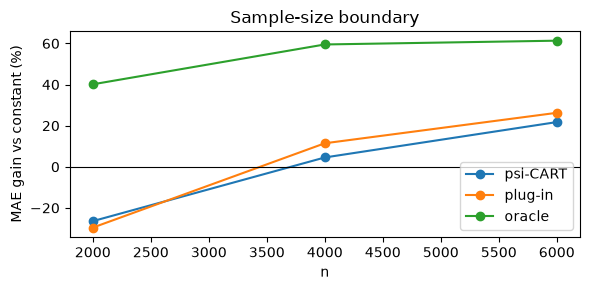

In [21]:
g17 = pd.read_csv(ROOT / 'results' / 'gate17_summary.csv')
print('Gate 17 - sample-size boundary. rel_gain is the MAE improvement over the')
print('constant model (%). Oracle rows select no rule, so their rule-level')
print('columns (target_corr, jaccard, purity, ...) are undefined and stay NaN.')
display(g17.round(4))
fig, ax = plt.subplots(figsize=(6, 3))
for t, lab in (('psi', 'psi-CART'), ('plugin', 'plug-in'), ('oracle', 'oracle')):
    d = g17[g17.target == t]
    ax.plot(d.n, d.rel_gain, marker='o', label=lab)
ax.axhline(0, color='k', lw=0.8)
ax.set_xlabel('n')
ax.set_ylabel('MAE gain vs constant (%)')
ax.set_title('Sample-size boundary')
ax.legend()
plt.tight_layout()
plt.show()

In [22]:
g21 = pd.read_csv(ROOT / 'results' / 'gate21_summary.csv')
print('Gate 21 - max-mean vs support-constrained selection (single region).')
print('arm C is the support-constrained (C200) rule.')
display(g21.round(4))

Gate 21 - max-mean vs support-constrained selection (single region).
arm C is the support-constrained (C200) rule.


,kappa,censoring,arm,reps,support,captured_uncommit,purity,capture,jaccard,stability,mae,const_mae,delta,commit_rate,coverage,per_treated,efficiency,captured_commit,null_rate,beneficial_rate
0,0.0,conditional,A,40,284.600,0.2293,0.6256,0.2278,0.2165,0.0350,0.0583,0.0733,-0.0150,42.5,0.0510,0.1682,0.8473,0.1829,0.0000,100.0000
1,0.0,conditional,B,40,418.725,0.3525,0.7813,0.3506,0.3279,0.0462,0.0586,0.0733,-0.0147,60.0,0.0848,0.1701,0.8604,0.3002,0.0000,100.0000
2,0.0,conditional,C,40,649.700,0.5164,0.8213,0.5140,0.4624,0.0412,0.0587,0.0733,-0.0146,80.0,0.1419,0.1624,0.8365,0.4578,0.0000,100.0000
3,0.0,conditional,D,40,577.050,0.2294,0.4140,0.2295,0.2028,0.0325,0.0588,0.0733,-0.0145,35.0,0.0486,0.1543,0.7787,0.1707,14.2857,85.7143
4,3.0,marginal,A,40,445.950,0.3565,0.6919,0.3549,0.3265,0.0425,0.0601,0.0718,-0.0117,55.0,0.0816,0.1639,0.8252,0.2882,4.5455,95.4545
5,3.0,marginal,B,40,509.200,0.4260,0.8098,0.4241,0.3942,0.0462,0.0602,0.0718,-0.0115,62.5,0.0943,0.1756,0.8829,0.3426,0.0000,100.0000
6,3.0,marginal,C,40,665.100,0.5483,0.8137,0.5452,0.5052,0.0412,0.0602,0.0718,-0.0116,80.0,0.1338,0.1695,0.8522,0.4739,0.0000,100.0000
7,3.0,marginal,D,40,665.275,0.2733,0.4061,0.2741,0.2336,0.0238,0.0606,0.0718,-0.0112,37.5,0.0775,0.1400,0.7348,0.2030,13.3333,86.6667


In [23]:
g23 = pd.read_csv(ROOT / 'results' / 'gate23_summary.csv')
g24 = pd.read_csv(ROOT / 'results' / 'gate24_summary.csv')
print('Gate 23 - two-region confirmation (C200 vs max-mean).')
display(g23.round(4))
print('Gate 24 - two-region joint nuisance stress.')
display(g24.round(4))

Gate 23 - two-region confirmation (C200 vs max-mean).


,config,reps,support,capture,purity,capture_region,j_true,jf_mean,jf_median,jf_q25,jf_q75,freq_full,jt_mean,freq_true,commit,coverage,per_treated,efficiency,captured_commit,null_rate,beneficial_rate,mae,delta
0,A,40,247.975,0.1485,0.7742,0.1303,0.1270,0.1597,0.1078,0.0483,0.2106,2.875,0.1393,0.0,45.0,0.0402,0.1728,0.8661,0.0980,0.0,100.0,0.0695,-0.0120
1,B,40,310.900,0.1941,0.8260,0.1698,0.1655,0.2051,0.1407,0.0682,0.2786,4.500,0.1574,0.0,55.0,0.0568,0.1752,0.8781,0.1412,0.0,100.0,0.0697,-0.0118
2,C100,40,433.025,0.2457,0.8465,0.2169,0.2012,0.1970,0.1226,0.0607,0.2653,4.375,0.1393,0.0,62.5,0.0840,0.1699,0.8669,0.1888,0.0,100.0,0.0698,-0.0117
3,C200,40,677.450,0.3642,0.8202,0.3260,0.2947,0.2745,0.2260,0.1267,0.3654,5.375,0.2339,0.0,70.0,0.1292,0.1628,0.8355,0.2844,0.0,100.0,0.0695,-0.0120
4,C400,40,916.175,0.4411,0.7776,0.4001,0.3446,0.3139,0.2681,0.1600,0.4252,5.375,0.2963,0.0,75.0,0.1618,0.1577,0.8157,0.3454,0.0,100.0,0.0697,-0.0118
5,D,40,565.525,0.2096,0.6677,0.2063,0.1788,0.1558,0.0857,0.0331,0.1994,3.000,0.1599,0.0,52.5,0.0840,0.1314,0.6671,0.1492,0.0,100.0,0.0699,-0.0116


Gate 24 - two-region joint nuisance stress.


,config,reps,support,capture,purity,capture_region,j_true,jf_mean,jf_median,freq_full,jt_mean,commit,coverage,per_treated,efficiency,captured_commit,null_rate,beneficial_rate,mae,delta,ate_bias
0,A,40,290.075,0.1719,0.7941,0.1560,0.1481,0.1484,0.0974,2.250,0.1383,30.0,0.0468,0.1718,0.8748,0.1146,0.0,100.0,0.0718,-0.0088,-0.0078
1,C200,40,741.950,0.3505,0.7388,0.3230,0.2759,0.2197,0.1762,2.875,0.2279,57.5,0.1479,0.1511,0.8192,0.2855,0.0,100.0,0.0721,-0.0085,-0.0078
2,C400,40,1046.075,0.4656,0.7420,0.4354,0.3597,0.2999,0.2697,3.875,0.2978,77.5,0.2283,0.1399,0.7633,0.4072,0.0,100.0,0.0717,-0.0089,-0.0078


In [24]:
g22 = pd.read_csv(ROOT / 'results' / 'gate22_summary.csv')
print('Gate 22 - stability measured by refitting the whole procedure on')
print('disjoint discovery half-samples (not by resampling within one fit).')
display(g22.round(4))

Gate 22 - stability measured by refitting the whole procedure on
disjoint discovery half-samples (not by resampling within one fit).


,kappa,censoring,config,reps,jf_mean,jf_median,jf_q25,jf_q75,jf_min,freq_full,jt_mean,freq_true,j_full_true,capture_full,purity_full
0,0.0,conditional,A,40,0.2531,0.1936,0.1078,0.3623,0.0197,6.500,0.2517,2.000,0.3484,0.3760,0.7686
1,0.0,conditional,B,40,0.2723,0.2153,0.1200,0.3960,0.0271,6.875,0.2732,2.250,0.3723,0.4014,0.8115
2,0.0,conditional,C100,40,0.2637,0.1957,0.1066,0.3831,0.0193,6.750,0.2517,2.000,0.4750,0.5316,0.8467
3,0.0,conditional,C200,40,0.3413,0.2968,0.1718,0.4905,0.0243,9.000,0.3474,3.500,0.5609,0.6213,0.8601
4,0.0,conditional,C400,40,0.4018,0.3799,0.2314,0.5499,0.0521,10.250,0.3982,4.250,0.6120,0.6985,0.8523
5,0.0,conditional,D,40,0.1791,0.1112,0.0264,0.2522,0.0003,3.750,0.1656,1.625,0.2397,0.2625,0.4695
6,3.0,marginal,A,40,0.1988,0.1407,0.0699,0.2751,0.0040,4.000,0.2396,2.125,0.3169,0.3433,0.6603
7,3.0,marginal,B,40,0.2742,0.2220,0.1092,0.3855,0.0199,5.750,0.2678,2.250,0.4161,0.4633,0.8158
8,3.0,marginal,C100,40,0.2315,0.1607,0.0795,0.3218,0.0034,5.000,0.2396,2.125,0.4434,0.5032,0.7579
9,3.0,marginal,C200,40,0.3178,0.2826,0.1538,0.4445,0.0125,6.625,0.3336,3.250,0.5221,0.6226,0.7951


In [25]:
g25 = pd.read_csv(ROOT / 'results' / 'gate25_summary.csv')
g26 = pd.read_csv(ROOT / 'results' / 'gate26_summary.csv')
print('Gate 25 - two-leaf rule list (rejected: capture up, purity down).')
display(g25.round(4))
print('Gate 26 - flexible DR-learner plus distillation (rejected: purer but narrower).')
display(g26.round(4))

Gate 25 - two-leaf rule list (rejected: capture up, purity down).


,condition,model,reps,n_leaves,fallback,support,support1,overlap,both,capture,purity,capture_region,j_true,jf_mean,freq_full,commit,coverage,per_treated,efficiency,captured_commit,null_rate,mae,delta
0,clean,A,40,1.000,0.0,344.525,344.525,0.0,0.0,0.2046,0.7932,0.1819,0.1738,0.1733,2.125,40.0,0.0628,0.1753,0.8818,0.1540,0.0000,0.0690,-0.0137
1,clean,C200,40,1.000,0.0,744.700,744.700,0.0,0.0,0.4143,0.8618,0.3703,0.3367,0.2743,4.250,75.0,0.1646,0.1679,0.8662,0.3670,0.0000,0.0689,-0.0138
2,clean,C400,40,1.000,0.0,900.575,900.575,0.0,0.0,0.4526,0.7936,0.4106,0.3650,0.3196,6.125,82.5,0.1886,0.1659,0.8583,0.4137,0.0000,0.0689,-0.0138
3,clean,LIST,40,1.975,2.5,1331.550,744.700,0.0,0.0,0.5835,0.6962,0.5391,0.4194,0.3564,3.500,85.0,0.2508,0.1578,0.8681,0.4892,0.0000,0.0689,-0.0138
4,stress,A,40,1.000,0.0,398.375,398.375,0.0,0.0,0.2361,0.7411,0.2106,0.2002,0.1745,3.000,52.5,0.0828,0.1575,0.7945,0.2000,4.7619,0.0685,-0.0136
5,stress,C200,40,1.000,0.0,773.175,773.175,0.0,0.0,0.4206,0.8444,0.3769,0.3400,0.2742,4.750,77.5,0.1730,0.1649,0.8546,0.3788,0.0000,0.0685,-0.0136
6,stress,C400,40,1.000,0.0,886.950,886.950,0.0,0.0,0.4633,0.8170,0.4202,0.3747,0.3220,6.125,85.0,0.2015,0.1600,0.8302,0.4300,0.0000,0.0683,-0.0137
7,stress,LIST,40,1.975,2.5,1409.975,773.175,0.0,0.0,0.5809,0.6708,0.5447,0.4123,0.3509,3.250,85.0,0.2733,0.1461,0.8292,0.4872,0.0000,0.0684,-0.0137


Gate 26 - flexible DR-learner plus distillation (rejected: purer but narrower).


,kind,arm,reps,support,n_cond,capture,purity,j_true,jf_mean,freq_full,commit,coverage,per_treated,efficiency,captured_commit,null_rate,mae,delta
0,single,C200,40,691.775,2.875,0.5477,0.8293,0.5002,0.3019,6.375,67.5,0.1253,0.1772,0.9029,0.4505,0.0,0.0525,-0.0192
1,single,FLEX,40,509.600,2.800,0.4537,0.8970,0.4270,0.3183,5.625,80.0,0.1096,0.1823,0.9170,0.3989,0.0,0.0572,-0.0145
2,two,C200,40,645.850,2.900,0.3721,0.8321,0.3074,0.2620,4.250,67.5,0.1285,0.1676,0.8504,0.3047,0.0,0.0690,-0.0124
3,two,FLEX,40,478.350,2.700,0.2987,0.8900,0.2521,0.2757,6.750,80.0,0.1022,0.1743,0.8739,0.2563,0.0,0.0698,-0.0117


In [26]:
g28 = pd.read_csv(ROOT / 'results' / 'gate28_summary.csv')
print('Gate 28 - formal C200 vs SCRE head-to-head, identical splits, 40 seeds.')
display(g28.round(4))
print('SCRE has lower MAE; C200 has higher purity and per-treated benefit,')
print('and treats far fewer patients. Both have a 0% null-treatment rate.')

Gate 28 - formal C200 vs SCRE head-to-head, identical splits, 40 seeds.


,kind,method,reps,ok,mae,spearman,capture,purity,per_treated,efficiency,null_rate,coverage,rules,commit
0,single,C200,40,100.0,0.0562,0.5980,0.5906,0.8563,0.1678,0.8825,0.0,0.1745,1.000,87.5
1,single,SCRE,40,100.0,0.0519,0.5962,0.9470,0.4331,0.0843,0.9470,0.0,0.5442,1.300,100.0
2,two,C200,40,100.0,0.0715,0.4414,0.3343,0.8699,0.1679,0.8496,0.0,0.1396,1.000,80.0
3,two,SCRE,40,100.0,0.0685,0.4919,0.8020,0.5849,0.0979,0.8020,0.0,0.5599,1.175,100.0


SCRE has lower MAE; C200 has higher purity and per-treated benefit,
and treats far fewer patients. Both have a 0% null-treatment rate.


### Why these metrics are not computed on the raw ACTG175 data

MAE, capture, purity, Jaccard, per-treated benefit, efficiency and the
null-treatment rate all compare an estimate with the **true** individual effect
$\tau_i$. ACTG175 has no known counterfactual truth, so those quantities are
undefined there, not merely missing. The cell below runs **one replication** of
the semi-synthetic design (ACTG175 covariates, simulated outcomes, both methods
on the same split) so you can watch the metrics being computed instead of
reading them from a saved CSV. It takes about a minute.

In [27]:
from ciscarl2.gate23 import _config23
from ciscarl2.gate26 import _calibrate_kind
from ciscarl2.gate28 import run_rep

print("Simulating one single-region replication on the ACTG175 covariate matrix...")
_cfg = _config23()
_lam = _calibrate_kind(_cfg, "single")
live = pd.DataFrame(run_rep(0, "single", _cfg, _lam))

show = live[["method", "mae", "spearman", "capture", "purity",
             "per_treated", "efficiency", "coverage", "committed", "n_rules"]]
display(show.round(3))

_c = live[live.method == "C200"].iloc[0]
if (live.method == "SCRE").any():
    _s = live[live.method == "SCRE"].iloc[0]
    print(f"true effects known -> MAE {_c.mae:.4f} (C200) vs {_s.mae:.4f} (SCRE)")
    print("lower MAE on this seed:", "C200" if _c.mae < _s.mae else "SCRE")
else:
    print(f"true effects known -> MAE {_c.mae:.4f} (C200); SCRE not installed "
          "(set SCRE_PATH to enable the comparator)")
print()
print("This is 1 of the 40 seeds behind the published table. A single")
print("replication can reverse the ranking; the claim is the paired average,")
print("not any one seed.")

Simulating one single-region replication on the ACTG175 covariate matrix...


,method,mae,spearman,capture,purity,per_treated,efficiency,coverage,committed,n_rules
0,C200,0.049,0.675,0.506,1.000,0.198,0.989,0.132,True,1
1,SCRE,0.053,0.607,0.936,0.473,0.091,0.936,0.530,True,1


true effects known -> MAE 0.0491 (C200) vs 0.0528 (SCRE)
lower MAE on this seed: C200

This is 1 of the 40 seeds behind the published table. A single
replication can reverse the ranking; the claim is the paired average,
not any one seed.


### Gate 30 - which knobs actually improve the model?

A sweep of every remaining knob, tuned on 40 seeds and confirmed on 40 fresh
seeds, with SCRE fitted on the same splits. One change survived: **shrinkage**
of the leaf effects toward the marginal average, used only for prediction
(`C200-S`). It lowers MAE, and it leaves purity, capture, commitment and the
selected rule **exactly** unchanged, because it never touches the decision.
Depth 4 is clearly worse; leaf-size changes do nothing; the commitment threshold
is a policy dial, not an accuracy lever.

In [28]:
g30v = pd.read_csv(ROOT / "results" / "gate30_variant_table.csv")
g30h = pd.read_csv(ROOT / "results" / "gate30_headtohead.csv")
g30s = pd.read_csv(ROOT / "results" / "gate30_smalln_summary.csv")

print("Variant sweep, pooled over 80 paired replications "
      "(negative d_mae = better than the frozen model):")
display(g30v[g30v.block == "pooled"][
    ["kind", "variant", "mae", "mae_base", "d_mae", "lo", "hi", "p"]
].round(4))

print("Head-to-head with SCRE on the same 80 splits:")
display(g30h[["kind", "method", "mae", "scre_mae", "d_mae", "lo", "hi", "p",
              "purity", "capture", "per_treated", "coverage"]].round(3))

print("Support floor: absolute 200 patients vs 5% of the discovery set.")
display(g30s[["n", "variant", "mae", "purity", "capture", "commit",
              "fallback", "support"]].round(3))

Variant sweep, pooled over 80 paired replications (negative d_mae = better than the frozen model):


,kind,variant,mae,mae_base,d_mae,lo,hi,p
12,single,V2,0.0525,0.0576,-0.0051,-0.0077,-0.0025,0.0000
13,single,V3a,0.0575,0.0576,-0.0001,-0.0004,0.0000,0.1592
14,single,V3b,0.0581,0.0576,0.0005,0.0001,0.0010,0.0160
15,single,V4a,0.0575,0.0576,-0.0002,-0.0014,0.0011,0.7616
16,single,V4b,0.0578,0.0576,0.0002,-0.0011,0.0015,0.7880
17,single,V5,0.0675,0.0576,0.0099,0.0080,0.0117,0.0000
30,two,V2,0.0680,0.0707,-0.0026,-0.0048,-0.0005,0.0144
31,two,V3a,0.0705,0.0707,-0.0001,-0.0004,0.0000,0.1308
32,two,V3b,0.0711,0.0707,0.0004,0.0000,0.0008,0.0192
33,two,V4a,0.0709,0.0707,0.0003,-0.0008,0.0013,0.6752


Head-to-head with SCRE on the same 80 splits:


,kind,method,mae,scre_mae,d_mae,lo,hi,p,purity,capture,per_treated,coverage
0,single,C200,0.058,0.051,0.006,0.003,0.009,0.000,0.890,0.465,0.174,0.133
1,single,C200-S,0.053,0.051,0.001,-0.002,0.004,0.482,0.890,0.465,0.174,0.133
2,two,C200,0.071,0.068,0.003,0.000,0.006,0.044,0.858,0.277,0.164,0.117
3,two,C200-S,0.068,0.068,0.000,-0.002,0.003,0.764,0.858,0.277,0.164,0.117


Support floor: absolute 200 patients vs 5% of the discovery set.


,n,variant,mae,purity,capture,commit,fallback,support
0,1000,abs200,0.121,0.614,0.105,27.5,80.0,114.750
1,1000,prop5,0.122,0.624,0.102,27.5,0.0,87.300
2,2000,abs200,0.104,0.468,0.096,17.5,0.0,373.075
3,2000,prop5,0.101,0.728,0.127,30.0,0.0,128.900
4,4000,abs200,0.079,0.710,0.311,55.0,0.0,450.550
5,4000,prop5,0.081,0.804,0.281,55.0,0.0,322.325


## Part 8 — ACTG175 interpretation

In [29]:
print('CISCaRL C200 on ACTG175')
print('overall tau(730):', f'{ov[0]:+.3f}', f'[{ov[1]:+.3f}, {ov[2]:+.3f}]')
print('selected rule:', rule_txt)
print('discovery support:', int(sup[j]), '| support >=200 met:', not fallback)
print('validation tau:', f'{eff_v:+.3f}', '| LCB:', f'{lcb:+.3f}',
      '| committed:', commit)
print('assessment rule tau:', f'{ru[0]:+.3f}', f'[{ru[1]:+.3f}, {ru[2]:+.3f}]',
      '| n =', ru[3])
print('decision:', verdict)
print()
print('Why INSUFFICIENT: the selected leaf has 62 discovery patients, below the')
print('200-patient support bar, and its validation LCB is negative. The abstention')
print('layer therefore refuses to commit; the +0.540 assessment estimate is')
print('descriptive only (n=30) and is not a validated subgroup effect.')
print('No MAE / capture / purity on ACTG175: those need ground truth.')

CISCaRL C200 on ACTG175
overall tau(730): +0.143 [+0.025, +0.262]
selected rule: cd40 <= 343.5 & age > 28.5 & homo <= 0.5
discovery support: 62 | support >=200 met: False
validation tau: +0.085 | LCB: -0.226 | committed: False
assessment rule tau: +0.540 [+0.178, +0.901] | n = 30
decision: INSUFFICIENT

Why INSUFFICIENT: the selected leaf has 62 discovery patients, below the
200-patient support bar, and its validation LCB is negative. The abstention
layer therefore refuses to commit; the +0.540 assessment estimate is
descriptive only (n=30) and is not a validated subgroup effect.
No MAE / capture / purity on ACTG175: those need ground truth.


## Part 9 — Conclusions and reproducibility

* The model is usable from roughly n ≈ 6000; at ACTG175 scale the support ≥200
  constraint cannot be met and the commitment layer correctly abstains.
* On simulated DGPs, support-constrained selection improves capture and
  ground-truth recovery over max-mean selection, at purity 0.81–0.86.
* SCRE has lower patient-level MAE; C200 has higher purity, higher per-treated
  benefit and an explicit abstention layer.
* ACTG175 is an illustration, not clinical validation.

In [30]:
RUN_AUDIT = False
if RUN_AUDIT:
    from ciscarl2.audit import main as audit_main
    print("audit failures:", audit_main())
else:
    print("Audit: `python -m ciscarl2.audit` (core checks passed in FINAL_AUDIT.md).")
print("ACTG175 split seed:", SEED)
print("Simulation seed ranges: 180100-180439, 190100-190339, 200100-200139,")
print("  210100-210139, 230100-230139, 240100-240139, 250100-250139,")
print("  260100-260139, 270100-270139, 280100-280139, 290100-290139, 300100-300139.")
print("Result files: results/gate17, gate21, gate22, gate23, gate24, gate25,")
print("  gate26, gate28 summaries; results/FINAL_AUDIT.md; results/actg175_c200.md.")

Audit: `python -m ciscarl2.audit` (core checks passed in FINAL_AUDIT.md).
ACTG175 split seed: 2024
Simulation seed ranges: 180100-180439, 190100-190339, 200100-200139,
  210100-210139, 230100-230139, 240100-240139, 250100-250139,
  260100-260139, 270100-270139, 280100-280139, 290100-290139, 300100-300139.
Result files: results/gate17, gate21, gate22, gate23, gate24, gate25,
  gate26, gate28 summaries; results/FINAL_AUDIT.md; results/actg175_c200.md.


### Final contribution

An honest evaluation of an interpretable survival subgroup model: cross-fitted
AIPW estimation, support-constrained rule selection, validation-based commitment,
and a measured operating range. The model is not universally better than SCRE;
its advantage is precision and abstention, not accuracy.